# strengthOfSchedule — how hard was each team's schedule?

**Theory:** some teams face tougher opponents than others, depending on who they play and when.

Regular season only (byes excluded):

1. **Score distributions:** points against, points for and point differential per game, one
   panel per team.
2. **Points against by week:** when each team ran into big scores.
3. **Opponent strength vs. points faced:** separates *facing good teams* from *facing teams on
   a hot week*.
4. **Points scored each week:** every team's score against that week's median.
5. **Regressions:** how strength-of-schedule metrics relate to wins, this season.
6. **Pooled regressions:** the same models on full 2022–2025 seasons (40 team-seasons).

Points against measures how well your opponent played *that week*. Opponent strength (their
average in their other games) measures how good they are in general. The gap between them is luck.

In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from adjustText import adjust_text
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

from fantasy_analysis.application.frames import team_results_frame
from fantasy_analysis.config import settings
from fantasy_analysis.infrastructure.espn import EspnLeagueRepository

pd.set_option("display.max_columns", 50)

SEASON = settings.espn_season

## Chart style

In [7]:
COLORS = {
    "surface": "#fcfcfb",
    "primary": "#0b0b0b",
    "secondary": "#52514e",
    "muted": "#898781",
    "grid": "#e1e0d9",
    "axis": "#c3c2b7",
    "series": "#2a78d6",  # blue: the single series in each panel
    "band": "#cde2fb",  # blue 100: +/-1 standard deviation band
    "band_neutral": "#e1e0d9",  # gray: +/-1 sd band behind blue/red bars
    "light": "#86b6ef",  # blue 250: opponent strength (expected)
    "dark": "#1c5cab",  # blue 550: points actually faced
    "above": "#2a78d6",  # diverging blue: scored above the week's median
    "below": "#e34948",  # diverging red: scored below the week's median
}
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update(
    {
        "figure.facecolor": COLORS["surface"],
        "axes.facecolor": COLORS["surface"],
        "savefig.facecolor": COLORS["surface"],
        "text.color": COLORS["primary"],
        "axes.labelcolor": COLORS["secondary"],
        "axes.edgecolor": COLORS["axis"],
        "xtick.color": COLORS["muted"],
        "ytick.color": COLORS["muted"],
        "axes.grid": True,
        "grid.color": COLORS["grid"],
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.titlesize": 10,
        "axes.titlelocation": "left",
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    }
)

## Load the season

In [8]:
league = EspnLeagueRepository.from_settings(settings).get_league(SEASON)
OWNERS = {t.name: t.owner.split()[0].capitalize() for t in league.teams}
OWNERS['The Germiphobes'] = 'Kinch'
OWNERS['Chase You to the Playoffs'] = 'Levitt'
OWNERS['#EATITFROMTHEBACK'] = 'Stein'


def with_owner(team: str, sep: str = " · ") -> str:
    return f"{team}{sep}{OWNERS[team]}"


results = team_results_frame(league)
games = results.loc[(results["kind"] == "REGULAR_SEASON") & (results["result"] != "BYE")].copy()

league_avg = games["points_for"].mean()  # every game's score is someone's points against
weeks = sorted(games["week"].unique())
print(f"{league.name} {SEASON}: {len(weeks)} regular-season weeks, league average {league_avg:.1f}")

The Corrupt League 2026: 7 regular-season weeks, league average 119.3


## Strength of schedule table

- `avg_pa`: average points scored against the team.
- `opp_strength`: how good its opponents are. For each game, the opponent's average score in
  *their other games*, so the game against this team doesn't count. Averaged over the
  team's schedule.
- `luck`: `avg_pa - opp_strength`. Positive means opponents played *above* their usual level
  against this team (unlucky). Negative means they played below it (lucky).

In [9]:
def schedule_table(games: pd.DataFrame) -> pd.DataFrame:
    """Strength-of-schedule metrics per team, from one season's regular-season games."""
    games = games.copy()

    def opponent_avg_elsewhere(row) -> float:
        """The opponent's average score in games not against this team."""
        opp_games = games.loc[
            (games["team"] == row["opponent"]) & (games["opponent"] != row["team"])
        ]
        return opp_games["points_for"].mean()

    games["opp_strength"] = games.apply(opponent_avg_elsewhere, axis=1)
    return (
        games.groupby("team")
        .agg(
            games=("week", "count"),
            wins=("result", lambda r: (r == "W").sum()),
            losses=("result", lambda r: (r == "L").sum()),
            avg_pf=("points_for", "mean"),
            avg_pa=("points_against", "mean"),
            med_pa=("points_against", "median"),
            sd_pa=("points_against", "std"),
            opp_strength=("opp_strength", "mean"),
        )
        .assign(luck=lambda df: df["avg_pa"] - df["opp_strength"])
        .sort_values("avg_pa", ascending=False)
    )


sos = schedule_table(games)
sos.round(1)

,games,wins,losses,avg_pf,avg_pa,med_pa,sd_pa,opp_strength,luck
team,,,,,,,,,
Will Power,7,1,6,117.4,138.3,136.4,20.6,121.6,16.7
Chubland,7,3,4,128.8,137.4,143.1,35.0,113.9,23.5
Benevolent Commish,7,3,4,127.9,122.5,130.5,21.1,117.7,4.8
Chase You to the Playoffs,7,2,5,117.5,122.0,115.0,16.5,119.7,2.3
On a Train Back to Boston,7,3,4,100.8,118.1,117.0,7.6,123.6,-5.6
I didnt hear no bell,7,2,5,103.4,116.1,120.1,17.6,127.0,-10.9
The Williams Family,7,5,2,124.8,111.6,107.6,13.9,112.3,-0.7
The Germiphobes,7,5,2,123.5,111.2,119.5,31.0,116.5,-5.3
To Infinity and Bijan,7,5,2,112.9,108.6,103.4,29.8,120.0,-11.3


## 1. Score distributions per team

One panel per team, for three per-game measures: points against, points for, and point
differential (points for minus points against). Bars count games in 10-point bins. The solid
line is the team's average and the shaded band is ±1 standard deviation around it. The dashed line
is the league reference.

### Points against

Hardest schedule first.

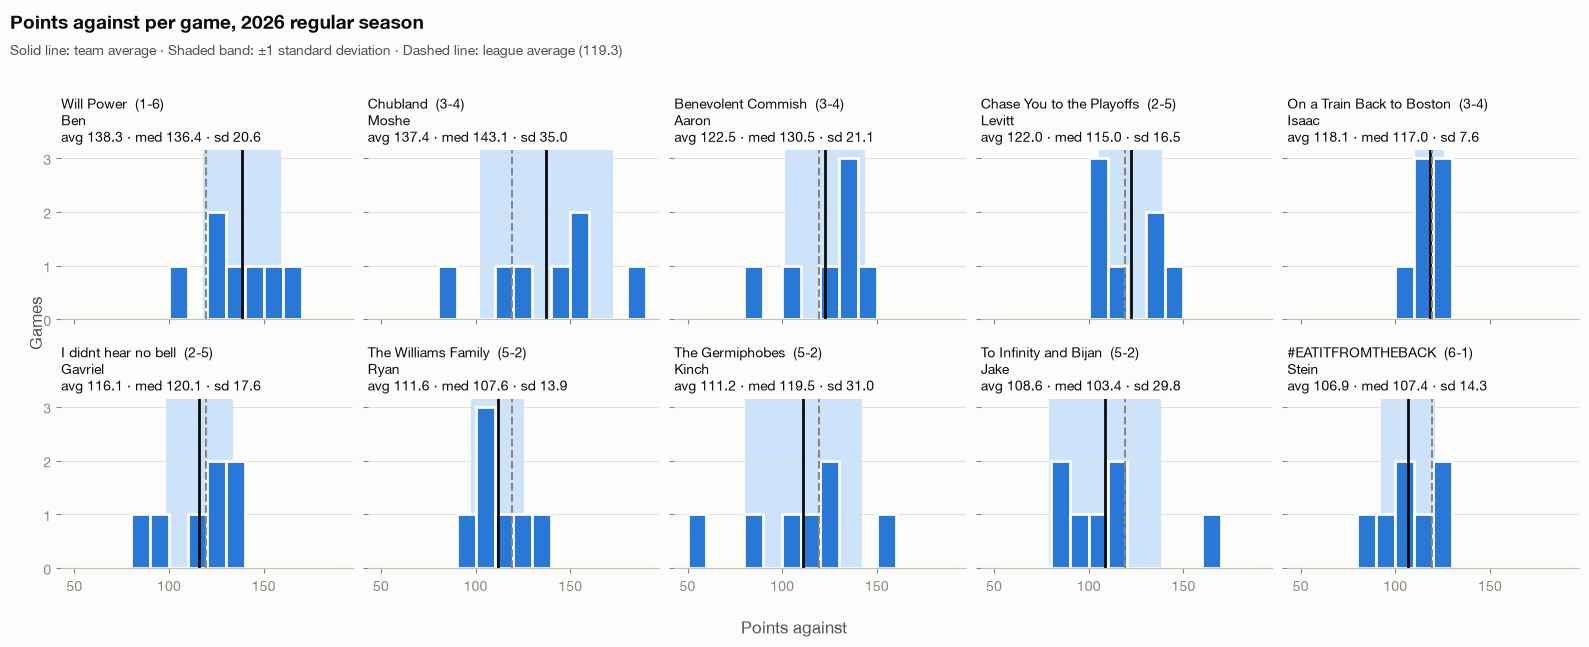

In [10]:
def plot_team_distributions(
    column: str,
    xlabel: str,
    title: str,
    reference: float,
    reference_label: str,
    diverging: bool = False,
) -> None:
    """One histogram panel per team for a per-game column of `games`, highest average first.

    With `diverging`, bars above 0 are blue and below 0 are red (for point differential).
    """
    stats = (
        games.groupby("team")[column]
        .agg(avg="mean", med="median", sd="std")
        .sort_values("avg", ascending=False)
    )
    ncols = 5
    nrows = math.ceil(len(stats) / ncols)
    lo = math.floor(games[column].min() / 10) * 10
    hi = math.ceil(games[column].max() / 10) * 10
    bins = np.arange(lo, hi + 10, 10)  # edges on multiples of 10, so 0 is an edge

    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows), sharex=True, sharey=True)
    for ax, (team, row) in zip(axes.flat, stats.iterrows(), strict=False):
        values = games.loc[games["team"] == team, column]
        ax.axvspan(
            row["avg"] - row["sd"], row["avg"] + row["sd"],
            color=COLORS["band_neutral" if diverging else "band"], linewidth=0, zorder=0,
        )
        _, edges, patches = ax.hist(
            values, bins=bins, color=COLORS["series"], edgecolor=COLORS["surface"], linewidth=2
        )
        if diverging:
            for patch, left, right in zip(patches, edges[:-1], edges[1:], strict=True):
                patch.set_facecolor(COLORS["above"] if left + right > 0 else COLORS["below"])
        ax.axvline(row["avg"], color=COLORS["primary"], linewidth=2)
        ax.axvline(reference, color=COLORS["muted"], linewidth=1.5, linestyle="--")
        record = sos.loc[team]
        ax.set_title(
            f"{team}  ({record['wins']:.0f}-{record['losses']:.0f})\n{OWNERS[team]}\n"
            f"avg {row['avg']:+.1f} · med {row['med']:+.1f} · sd {row['sd']:.1f}"
            if diverging
            else f"{team}  ({record['wins']:.0f}-{record['losses']:.0f})\n{OWNERS[team]}\n"
            f"avg {row['avg']:.1f} · med {row['med']:.1f} · sd {row['sd']:.1f}"
        )
        ax.grid(axis="x", visible=False)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    for ax in axes.flat[len(stats) :]:
        ax.axis("off")

    fig.supxlabel(xlabel, color=COLORS["secondary"])
    fig.supylabel("Games", color=COLORS["secondary"])
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    fig.text(0.01, 0.99, title, va="top", fontsize=14, fontweight="bold")
    subtitle = (
        "Solid line: team average · Shaded band: ±1 standard deviation · "
        f"Dashed line: {reference_label}"
    )
    if diverging:
        subtitle += " · Blue: games won · Red: games lost"
    fig.text(0.01, 0.94, subtitle, va="top", color=COLORS["secondary"], fontsize=10)
    plt.show()


plot_team_distributions(
    "points_against", "Points against", f"Points against per game, {SEASON} regular season",
    reference=league_avg, reference_label=f"league average ({league_avg:.1f})",
)

### Points for

Highest-scoring team first. The league average is the same number as for points against:
every team's score is its opponent's points against.

In [ ]:
plot_team_distributions(
    "points_for", "Points for", f"Points for per game, {SEASON} regular season",
    reference=league_avg, reference_label=f"league average ({league_avg:.1f})",
)

### Point differential

Points for minus points against, per game. Positive means the team won that game, so blue bars
are wins and red bars are losses. Best average margin first. A wide spread means a mix of
blowouts and close games.

In [ ]:
games["margin"] = games["points_for"] - games["points_against"]

plot_team_distributions(
    "margin", "Point differential (points for − points against)",
    f"Point differential per game, {SEASON} regular season",
    reference=0, reference_label="even (0)", diverging=True,
)

## 2. Points against by week

Same team order. Darker means the opponent scored more that week. This shows whether a tough
schedule was spread out or concentrated in a few weeks. The table below the chart has the
exact values.

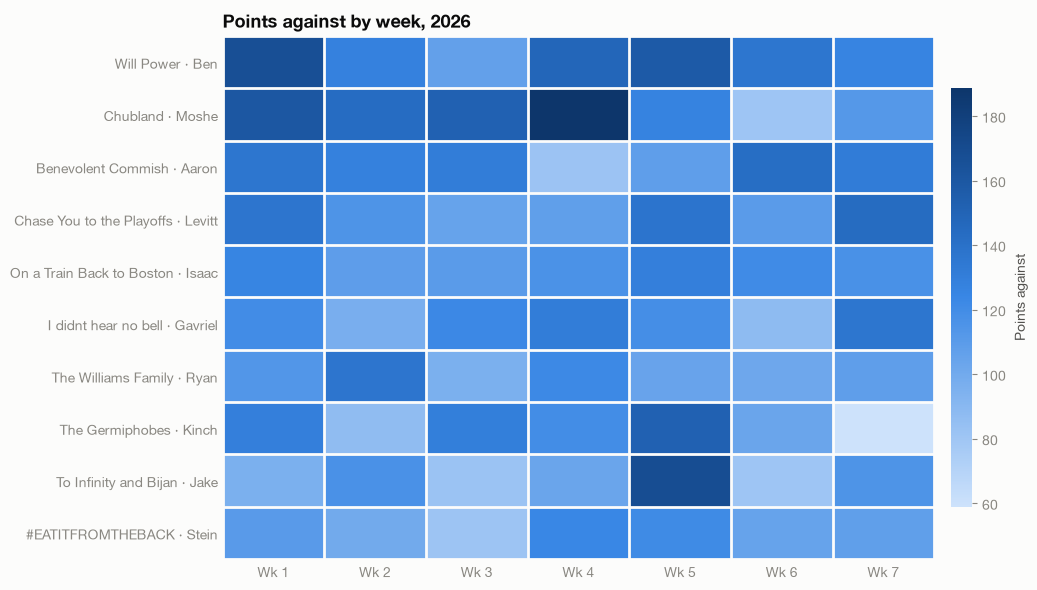

week,1,2,3,4,5,6,7
team,,,,,,,
Will Power,166.4,127.6,106.4,148.3,157.2,136.4,125.4
Chubland,159.8,143.1,151.9,188.6,125.9,80.7,111.9
Benevolent Commish,136.2,128.3,130.5,81.3,107.6,142.1,131.8
Chase You to the Playoffs,136.6,115.0,104.8,107.2,137.0,109.9,143.8
On a Train Back to Boston,125.3,108.3,110.0,116.1,129.1,120.7,117.0
I didnt hear no bell,120.1,96.9,122.4,131.1,118.6,87.5,135.9
The Williams Family,113.3,136.9,95.7,121.9,104.3,101.8,107.6
The Germiphobes,128.9,86.4,129.8,119.5,151.7,103.3,58.9
To Infinity and Bijan,95.5,116.5,82.1,103.4,167.9,80.3,114.7


In [11]:
pa_by_week = games.pivot(index="team", columns="week", values="points_against").loc[sos.index]

cmap = LinearSegmentedColormap.from_list("blue", BLUE_RAMP)
fig, ax = plt.subplots(figsize=(1.0 * len(weeks) + 4, 0.45 * len(sos) + 1.5))
im = ax.imshow(pa_by_week.to_numpy(), cmap=cmap, aspect="auto")
ax.set_xticks(range(len(weeks)), [f"Wk {w}" for w in weeks])
ax.set_yticks(range(len(sos)), [with_owner(t) for t in sos.index])
ax.tick_params(length=0)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
# 2px surface gaps between cells
ax.set_xticks(np.arange(-0.5, len(weeks)), minor=True)
ax.set_yticks(np.arange(-0.5, len(sos)), minor=True)
ax.grid(which="minor", color=COLORS["surface"], linewidth=2)
ax.tick_params(which="minor", length=0)
cbar = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cbar.set_label("Points against", color=COLORS["secondary"])
cbar.outline.set_visible(False)
ax.set_title(f"Points against by week, {SEASON}", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

pa_by_week.round(1)

## 3. Opponent strength vs. points actually faced

Light dot: how good the team's opponents are on average (`opp_strength`). Dark dot: what they
actually scored against this team (`avg_pa`). Rows run from hardest opponents down.

- Dark dot right of the light dot: opponents played above their usual level (unlucky).
- Dark dot left of it: opponents played below their usual level (lucky).

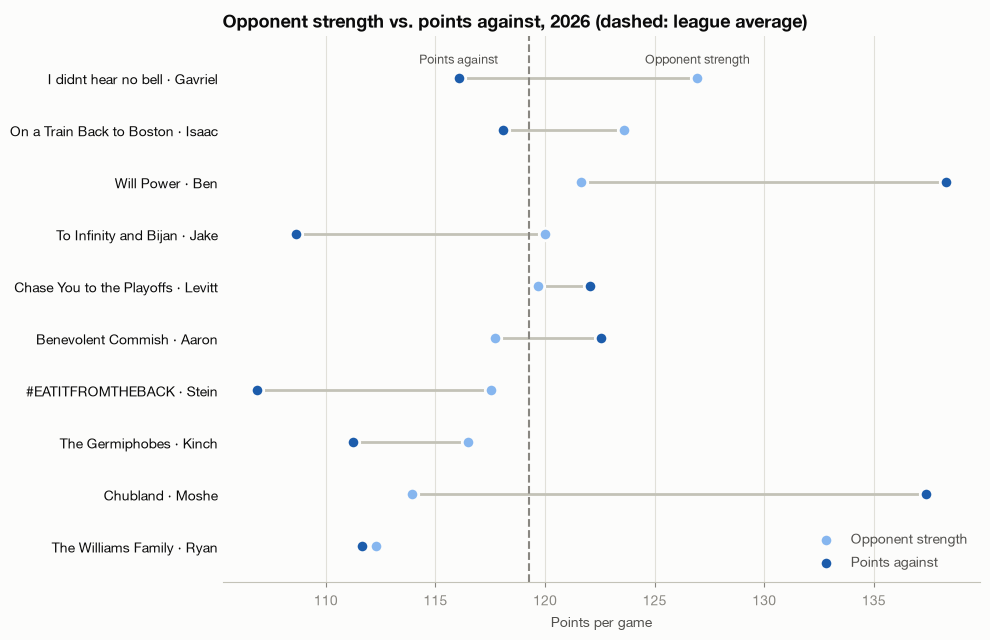

In [12]:
by_strength = sos.sort_values("opp_strength")  # hardest at the top after barh flips order
y = np.arange(len(by_strength))

fig, ax = plt.subplots(figsize=(10, 0.5 * len(by_strength) + 1.5))
ax.hlines(y, by_strength["opp_strength"], by_strength["avg_pa"], color=COLORS["axis"], linewidth=2)
ax.scatter(
    by_strength["opp_strength"], y, s=80, color=COLORS["light"],
    edgecolor=COLORS["surface"], linewidth=2, zorder=3, label="Opponent strength",
)
ax.scatter(
    by_strength["avg_pa"], y, s=80, color=COLORS["dark"],
    edgecolor=COLORS["surface"], linewidth=2, zorder=3, label="Points against",
)
ax.axvline(league_avg, color=COLORS["muted"], linewidth=1.5, linestyle="--")
ax.set_yticks(y, [with_owner(t) for t in by_strength.index])
ax.tick_params(axis="y", length=0, labelcolor=COLORS["primary"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Points per game")

# Direct labels on the top row only
top = by_strength.iloc[-1]
for x, label in ((top["opp_strength"], "Opponent strength"), (top["avg_pa"], "Points against")):
    ax.annotate(label, (x, y[-1]), xytext=(0, 10), textcoords="offset points",
                ha="center", fontsize=9, color=COLORS["secondary"])

ax.legend(loc="lower right", frameon=False, labelcolor=COLORS["secondary"])
ax.set_title(
    f"Opponent strength vs. points against, {SEASON} (dashed: league average)",
    fontsize=13, fontweight="bold",
)
ax.set_ylim(-0.7, len(by_strength) - 0.2)
fig.tight_layout()
plt.show()

## 4. Points scored each week, against the median

One panel per week. Each dot is a team's score, highest at the top. The vertical line is that
week's median. Blue means the team scored above the median, red means below. Beating the
median is roughly "would have beaten half the league that week".

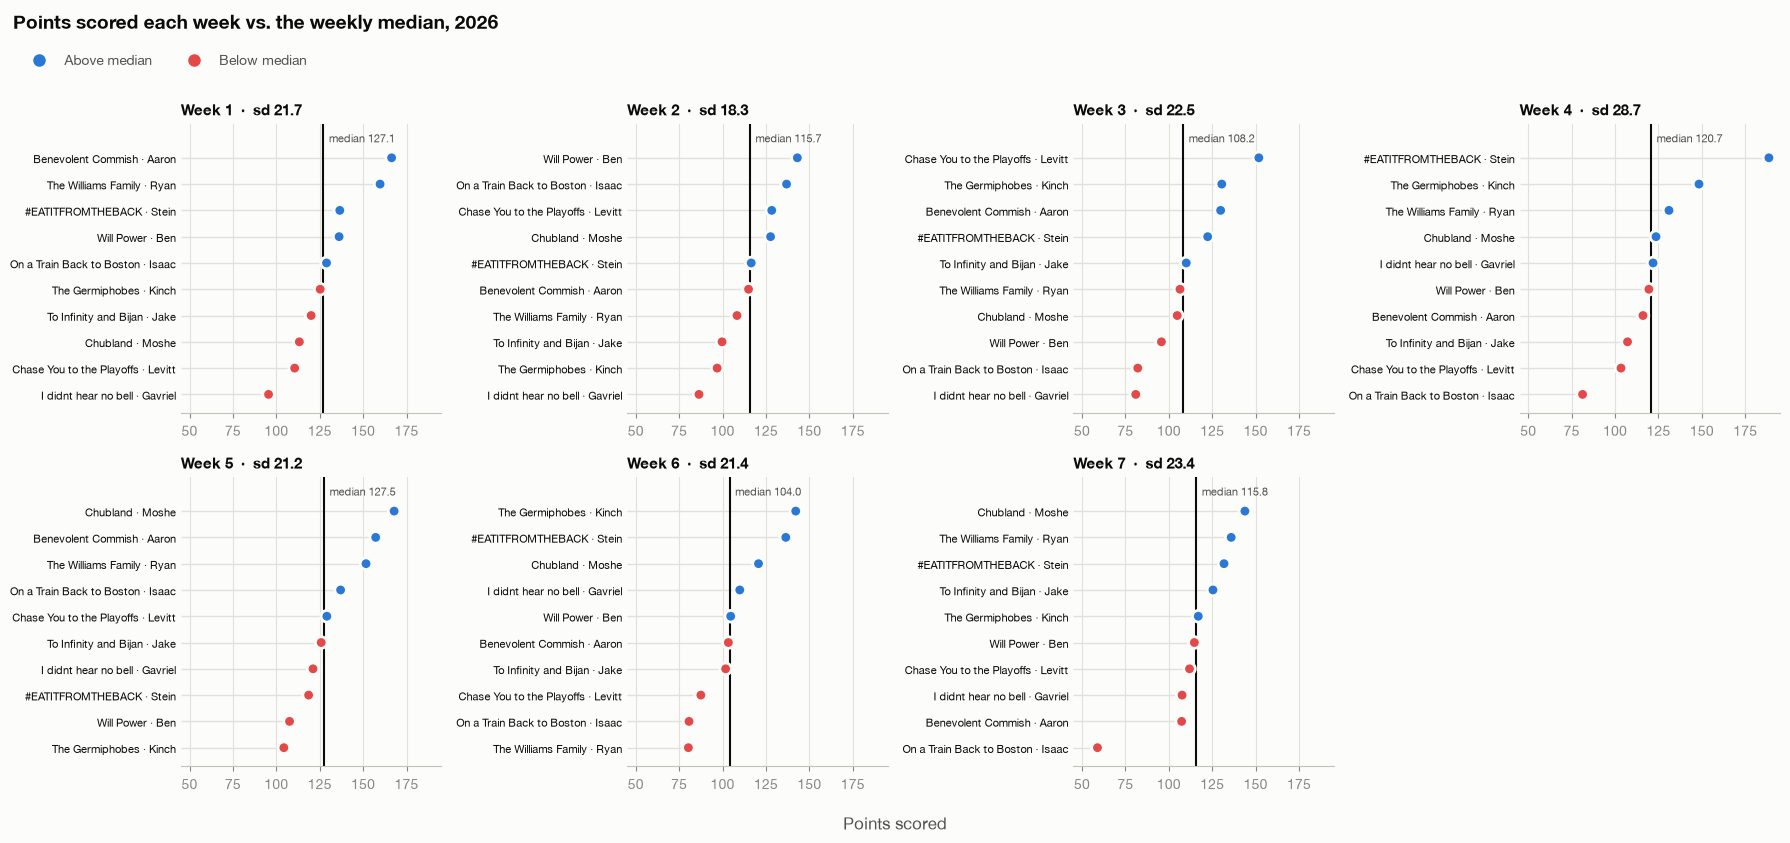

In [13]:
ncols = 4
nrows = math.ceil(len(weeks) / ncols)
x_lo = math.floor(games["points_for"].min() / 10) * 10 - 5
x_hi = math.ceil(games["points_for"].max() / 10) * 10 + 5

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.2 * nrows), sharex=True)
for ax, week in zip(axes.flat, weeks, strict=False):
    week_scores = games.loc[games["week"] == week].sort_values("points_for")
    median = week_scores["points_for"].median()
    sd = week_scores["points_for"].std()
    y = np.arange(len(week_scores))
    above = week_scores["points_for"] > median
    colors = np.where(above, COLORS["above"], COLORS["below"])

    ax.hlines(y, x_lo, week_scores["points_for"], color=COLORS["grid"], linewidth=1)
    ax.scatter(
        week_scores["points_for"], y, s=70, color=colors,
        edgecolor=COLORS["surface"], linewidth=2, zorder=3,
    )
    ax.axvline(median, color=COLORS["primary"], linewidth=1.5)
    ax.annotate(
        f"median {median:.1f}", (median, len(y) - 0.5), xytext=(4, 0),
        textcoords="offset points", fontsize=8, color=COLORS["secondary"], va="bottom",
    )
    ax.set_yticks(
        y, [with_owner(t) for t in week_scores["team"]], fontsize=8, color=COLORS["primary"]
    )
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(x_lo, x_hi)
    ax.set_ylim(-0.7, len(y) + 0.3)
    ax.set_title(f"Week {week}  ·  sd {sd:.1f}", fontsize=11, fontweight="bold")
    ax.tick_params(axis="x", labelbottom=True)  # sharex hides these above empty panels
for ax in axes.flat[len(weeks) :]:
    ax.axis("off")

fig.supxlabel("Points scored", color=COLORS["secondary"])
fig.tight_layout(rect=(0, 0, 1, 0.9 if nrows <= 2 else 0.94))
fig.text(
    0.01, 0.99, f"Points scored each week vs. the weekly median, {SEASON}",
    va="top", fontsize=14, fontweight="bold",
)
handles = [
    plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=COLORS[k], label=label)
    for k, label in (("above", "Above median"), ("below", "Below median"))
]
fig.legend(
    handles=handles, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncols=2,
    frameon=False, labelcolor=COLORS["secondary"],
)
plt.show()

Each team's score minus that week's median (positive = above), plus how many weeks it finished
above the median. Sorted by weeks above the median.

In [14]:
weekly_median = games.groupby("week")["points_for"].transform("median")
games["vs_median"] = games["points_for"] - weekly_median

vs_median = games.pivot(index="team", columns="week", values="vs_median")
vs_median.columns = [f"wk_{w}" for w in vs_median.columns]
vs_median["weeks_above"] = (vs_median > 0).sum(axis=1)
vs_median["avg_vs_median"] = vs_median.filter(like="wk_").mean(axis=1)
vs_median.sort_values(["weeks_above", "avg_vs_median"], ascending=False).round(1)

,wk_1,wk_2,wk_3,wk_4,wk_5,wk_6,wk_7,weeks_above,avg_vs_median
team,,,,,,,,,
#EATITFROMTHEBACK,9.5,0.8,14.1,67.9,-8.9,32.4,16.0,6,18.8
Chubland,-13.8,11.9,-3.4,2.9,40.4,16.7,28.0,5,11.8
The Williams Family,32.7,-7.4,-1.8,10.4,24.2,-23.7,20.1,4,7.8
The Germiphobes,-1.8,-18.8,22.3,27.7,-23.1,38.1,1.1,4,6.5
Benevolent Commish,39.3,-0.8,21.6,-4.6,29.8,-0.7,-8.5,3,10.9
Chase You to the Playoffs,-16.5,12.6,43.6,-17.3,1.6,-16.5,-3.9,3,0.5
Will Power,9.1,27.4,-12.5,-1.2,-19.9,0.7,-1.1,3,0.3
On a Train Back to Boston,1.8,21.1,-26.1,-39.4,9.5,-23.3,-56.9,3,-16.2
To Infinity and Bijan,-7.0,-16.0,1.8,-13.5,-1.6,-2.2,9.6,2,-4.1


## 5. Do strength-of-schedule metrics predict wins?

One data point per team. Each model regresses **wins** on one or more metrics:

| Model | Question |
|---|---|
| `wins ~ avg_pa` | Do teams that face more points win less? |
| `wins ~ opp_strength` | Do teams that face better opponents win less? |
| `wins ~ luck` | Do teams whose opponents overperform against them win less? |
| `wins ~ avg_pf` | Baseline: how much does a team's *own* scoring explain? |
| `wins ~ avg_pf + avg_pa` | How much does schedule add once scoring is accounted for? |

How to read the output: **coef** is the change in wins per 1 extra point per game.
**P>\|t\|** below 0.05 is the usual bar for "unlikely to be chance". **R-squared** is the share of
the variation in wins the model explains. With only one season of teams (n = 10), expect wide
confidence intervals. A slope can look large and still not be distinguishable from zero.

In [15]:
import warnings

# name -> (formula, the schedule/scoring term to report in the comparison table)
MODELS = {
    "Points against": ("wins ~ avg_pa", "avg_pa"),
    "Opponent strength": ("wins ~ opp_strength", "opp_strength"),
    "Luck": ("wins ~ luck", "luck"),
    "Points for (baseline)": ("wins ~ avg_pf", "avg_pf"),
    "Points for + points against": ("wins ~ avg_pf + avg_pa", "avg_pa"),
}


def fit_models(data: pd.DataFrame, models: dict) -> dict:
    with warnings.catch_warnings():
        # scipy warns that its kurtosis test needs n >= 20; the regression itself is unaffected
        warnings.filterwarnings("ignore", message=".*kurtosistest.*")
        return {name: smf.ols(formula, data=data).fit() for name, (formula, _) in models.items()}


def comparison_table(fits: dict, models: dict) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "model": name,
                "formula": formula,
                "term": term,
                "coef": fits[name].params[term],
                "ci_low": fits[name].conf_int().loc[term, 0],
                "ci_high": fits[name].conf_int().loc[term, 1],
                "p_value": fits[name].pvalues[term],
                "r_squared": fits[name].rsquared,
                "adj_r_squared": fits[name].rsquared_adj,
                "n": int(fits[name].nobs),
            }
            for name, (formula, term) in models.items()
        ]
    ).set_index("model")


reg_data = sos.reset_index()
fits = fit_models(reg_data, MODELS)
comparison = comparison_table(fits, MODELS)
comparison.round(3)

,formula,term,coef,ci_low,ci_high,p_value,r_squared,adj_r_squared,n
model,,,,,,,,,
Points against,wins ~ avg_pa,avg_pa,-0.115,-0.192,-0.038,0.009,0.597,0.547,10
Opponent strength,wins ~ opp_strength,opp_strength,-0.200,-0.459,0.060,0.114,0.283,0.193,10
Luck,wins ~ luck,luck,-0.073,-0.169,0.023,0.119,0.275,0.185,10
Points for (baseline),wins ~ avg_pf,avg_pf,0.069,-0.037,0.175,0.173,0.219,0.121,10
Points for + points against,wins ~ avg_pf + avg_pa,avg_pa,-0.116,-0.171,-0.061,0.002,0.829,0.780,10


### Regression plots

One panel per single-metric model. The line is the fitted regression and the shaded band is its
95% confidence interval. Points against, opponent strength and luck are the schedule metrics.
Points for is the baseline for comparison.

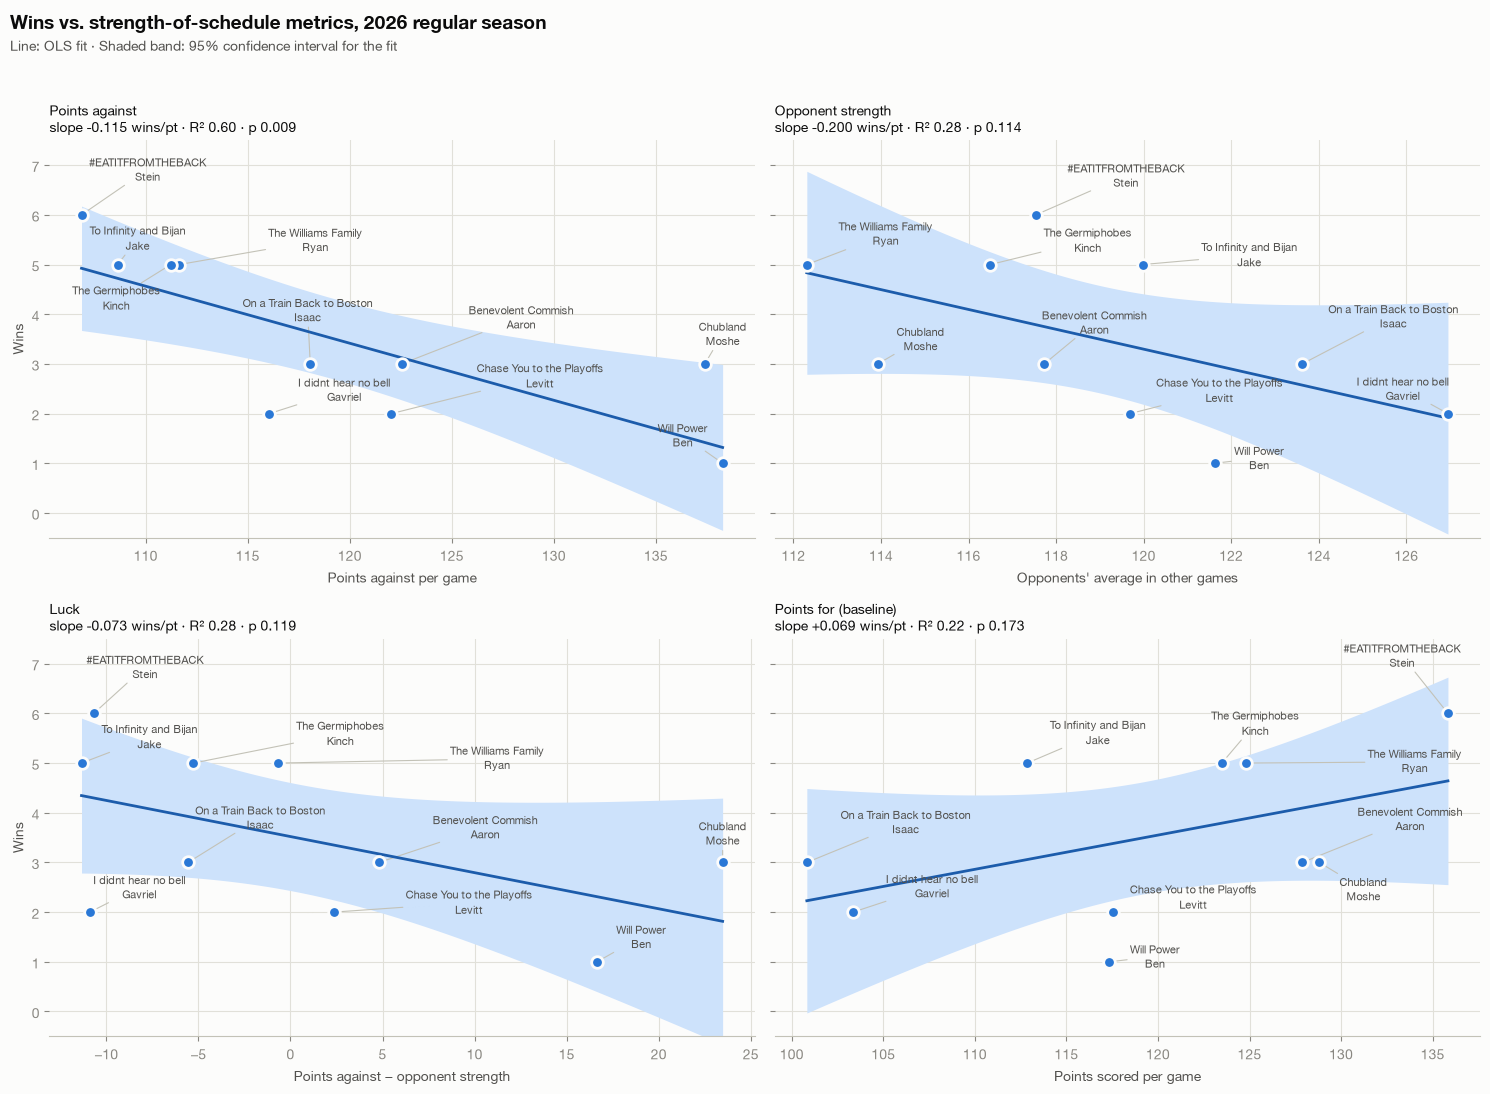

In [16]:
SINGLE = [
    ("Points against", "avg_pa", "Points against per game"),
    ("Opponent strength", "opp_strength", "Opponents' average in other games"),
    ("Luck", "luck", "Points against − opponent strength"),
    ("Points for (baseline)", "avg_pf", "Points scored per game"),
]


def plot_regressions(data: pd.DataFrame, fits: dict, title: str, label=None) -> None:
    """2x2 grid of wins vs. each single-metric model. `label(row)` names points, if given."""
    max_games = int(data["games"].max())
    fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharey=True)
    for ax, (name, col, xlabel) in zip(axes.flat, SINGLE, strict=True):
        fit = fits[name]
        x = data[col]
        grid = pd.DataFrame({col: np.linspace(x.min(), x.max(), 100)})
        pred = fit.get_prediction(grid).summary_frame(alpha=0.05)

        ax.fill_between(
            grid[col], pred["mean_ci_lower"], pred["mean_ci_upper"],
            color=COLORS["band"], linewidth=0,
        )
        ax.plot(grid[col], pred["mean"], color=COLORS["dark"], linewidth=2)
        ax.scatter(
            x, data["wins"], s=70, color=COLORS["series"],
            edgecolor=COLORS["surface"], linewidth=2, zorder=3,
        )
        ax.set_ylim(-0.5, max_games + 0.5)  # wins can't go outside 0..games played
        if label is not None:
            labels = [
                ax.text(
                    r[col], r["wins"], label(r),
                    fontsize=8, color=COLORS["secondary"], linespacing=1.1,
                )
                for _, r in data.iterrows()
            ]
            adjust_text(
                labels, x=x.to_numpy(), y=data["wins"].to_numpy(), ax=ax, expand=(1.3, 2.0),
                arrowprops={"arrowstyle": "-", "color": COLORS["axis"], "lw": 0.8},
            )

        slope, p = fit.params[col], fit.pvalues[col]
        ax.set_title(
            f"{name}\nslope {slope:+.3f} wins/pt · R² {fit.rsquared:.2f} · p {p:.3f}",
            fontsize=10,
        )
        ax.set_xlabel(xlabel)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    for ax in axes[:, 0]:
        ax.set_ylabel("Wins")

    fig.tight_layout(rect=(0, 0, 1, 0.92))
    fig.text(0.01, 0.99, title, va="top", fontsize=14, fontweight="bold")
    fig.text(
        0.01, 0.965, "Line: OLS fit · Shaded band: 95% confidence interval for the fit",
        va="top", color=COLORS["secondary"], fontsize=10,
    )
    plt.show()


plot_regressions(
    reg_data, fits, f"Wins vs. strength-of-schedule metrics, {SEASON} regular season",
    label=lambda r: with_owner(r["team"], sep="\n"),
)

### Full regression output

In [17]:
print(fits["Points against"].summary(title="Points against"))

                                Points against                                
Dep. Variable:                   wins   R-squared:                       0.597
Model:                            OLS   Adj. R-squared:                  0.547
Method:                 Least Squares   F-statistic:                     11.86
Date:                Sat, 31 Oct 2026   Prob (F-statistic):            0.00877
Time:                        00:12:15   Log-Likelihood:                -14.123
No. Observations:                  10   AIC:                             32.25
Df Residuals:                       8   BIC:                             32.85
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     17.1939      3.992      4.307      0.0

In [18]:
print(fits["Opponent strength"].summary(title="Opponent strength"))

                              Opponent strength                               
Dep. Variable:                   wins   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.193
Method:                 Least Squares   F-statistic:                     3.150
Date:                Sat, 31 Oct 2026   Prob (F-statistic):              0.114
Time:                        00:12:15   Log-Likelihood:                -17.010
No. Observations:                  10   AIC:                             38.02
Df Residuals:                       8   BIC:                             38.62
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       27.2690     13.401      2.035   

In [19]:
print(fits["Luck"].summary(title="Luck"))

                                     Luck                                     
Dep. Variable:                   wins   R-squared:                       0.275
Model:                            OLS   Adj. R-squared:                  0.185
Method:                 Least Squares   F-statistic:                     3.039
Date:                Sat, 31 Oct 2026   Prob (F-statistic):              0.119
Time:                        00:12:15   Log-Likelihood:                -17.060
No. Observations:                  10   AIC:                             38.12
Df Residuals:                       8   BIC:                             38.72
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.5209      0.471      7.471      0.0

In [20]:
print(fits["Points for (baseline)"].summary(title="Points for (baseline)"))

                            Points for (baseline)                             
Dep. Variable:                   wins   R-squared:                       0.219
Model:                            OLS   Adj. R-squared:                  0.121
Method:                 Least Squares   F-statistic:                     2.241
Date:                Sat, 31 Oct 2026   Prob (F-statistic):              0.173
Time:                        00:12:15   Log-Likelihood:                -17.435
No. Observations:                  10   AIC:                             38.87
Df Residuals:                       8   BIC:                             39.47
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -4.7181      5.511     -0.856      0.4

In [21]:
print(fits["Points for + points against"].summary(title="Points for + points against"))

                         Points for + points against                          
Dep. Variable:                   wins   R-squared:                       0.829
Model:                            OLS   Adj. R-squared:                  0.780
Method:                 Least Squares   F-statistic:                     16.99
Date:                Sat, 31 Oct 2026   Prob (F-statistic):            0.00206
Time:                        00:12:15   Log-Likelihood:                -9.8346
No. Observations:                  10   AIC:                             25.67
Df Residuals:                       7   BIC:                             26.58
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.8835      3.872      2.295      0.0

### Reading the combined model

`wins ~ avg_pf + avg_pa` asks: for two teams that score the same, how many wins does facing an
extra point per game cost? If `avg_pa` still has a clear negative coefficient here, schedule
matters beyond a team's own scoring. If its p-value is large, any schedule effect is too small
to see in this sample.

**"The condition number is large" note** in the outputs comes from the predictors sitting around
100–140 rather than near zero, which inflates the intercept's scale. It isn't a sign that
`avg_pf` and `avg_pa` are too correlated to separate. The coefficients and p-values are fine.

**More data helps most.** Section 6 pools four full seasons, giving 40 team-seasons instead
of 10.

## 6. Pooled seasons: 2022–2025

The same analysis on four complete seasons. Each **team-season** is one data point: 10 teams ×
4 seasons = 40 rows, each with a full 14-game regular season. Strength-of-schedule metrics are
computed within each season, so `opp_strength` compares a team only with that season's opponents.

The league format is the same in every season: 10 teams, 14 regular-season weeks, the same
starting lineup. The only change is the bench, which went from 7 spots to 6 in 2025. That
doesn't affect scoring.

Loading takes a little while (four full seasons of box scores).

In [ ]:
POOLED_SEASONS = [2022, 2023, 2024, 2025]

repo = EspnLeagueRepository.from_settings(settings)


def regular_season_games(league) -> pd.DataFrame:
    results = team_results_frame(league)
    return results.loc[(results["kind"] == "REGULAR_SEASON") & (results["result"] != "BYE")]


def season_table(season: int, league) -> pd.DataFrame:
    """One season's strength-of-schedule table, tagged with the season and each team's owner."""
    owners = {t.name: t.owner for t in league.teams}
    table = schedule_table(regular_season_games(league))
    return table.assign(season=season, owner=table.index.map(owners))


pooled_leagues = {season: repo.get_league(season) for season in POOLED_SEASONS}
pooled = pd.concat([season_table(s, lg) for s, lg in pooled_leagues.items()]).reset_index()

print(
    pooled.groupby("season")
    .agg(teams=("team", "count"), games_each=("games", "max"), total_wins=("wins", "sum"),
         avg_pf=("avg_pf", "mean"))
    .round(1)
)
pooled.round(1)

### Pooled models

The same five models, plus one more. Scoring levels differ from season to season (league average
points move around), so the last model adds a **season fixed effect**, `C(season)`, which
compares each team only with other teams from the same season.

In [ ]:
POOLED_MODELS = MODELS | {
    "Points for + points against + season": ("wins ~ avg_pf + avg_pa + C(season)", "avg_pa"),
}

pooled_fits = fit_models(pooled, POOLED_MODELS)
pooled_comparison = comparison_table(pooled_fits, POOLED_MODELS)
pooled_comparison.round(3)

### Pooled regression plots

40 points per panel, so points aren't labeled. The table above has every team-season.

In [ ]:
first, last = POOLED_SEASONS[0], POOLED_SEASONS[-1]
plot_regressions(
    pooled, pooled_fits,
    f"Wins vs. strength-of-schedule metrics, {first}–{last} regular seasons pooled "
    f"(n = {len(pooled)})",
)

### Full pooled regression output

In [ ]:
for name, fit in pooled_fits.items():
    print(fit.summary(title=f"{name} (pooled {first}–{last})"))
    print()

### This season vs. pooled

Each model's key coefficient, R² and p-value, from {SEASON} alone (n = 10) and from the pooled
seasons (n = 40). Agreement in sign and size suggests a real pattern rather than one season's
noise. A p-value that drops sharply with more data means the effect was real but the single
season was too small to show it.

In [ ]:
side_by_side = pd.concat(
    {
        f"{SEASON}": comparison[["term", "coef", "p_value", "r_squared"]],
        f"{first}–{last}": pooled_comparison[["coef", "p_value", "r_squared"]],
    },
    axis=1,
)
side_by_side.round(3)

## Caveats

- **Small samples.** Mid-season there are only a handful of games per team, so one blowout week
  moves a team's average a lot. Re-run as the season goes on, or set `SEASON` to a finished year
  (2019 onward).
- **`opp_strength` is an average, not a ranking of matchups.** A team can face strong opponents
  and still catch them on off weeks. That's what the luck column captures.
- **Correlation with record.** To test whether schedule actually decided standings, compare
  `luck` (or `avg_pa`) with wins in the table above.